# Content-based filtering: profil pengguna dan representasi item

[![Buka di Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/imamrozi/recsys-hibrida-multisinyal-notebooks/blob/main/notebooks/bab02_pendekatan_dasar/01_content_based_tfidf.ipynb)

**Buku pendamping:** *Sistem Rekomendasi Hibrida Multi-Sinyal: Rating, Sentimen, dan Emosi* · Bab 2 · Kode 2.1.1

**Tujuan belajar**

- Membangun profil pengguna sebagai rata-rata fitur item berbobot rating.
- Membandingkan representasi genre (satu-hot) dengan TF-IDF dari teks.
- Melihat langsung mengapa CBF cenderung menyempit (over-specialization).

> **Catatan jujur.** Semua data di notebook ini **simulasi** dan dibuat agar mudah dijalankan (CPU, hitungan detik). Angka yang keluar menunjukkan *perilaku metode*, bukan hasil empiris pada dataset nyata, dan tidak boleh dikutip sebagai bukti. Kode bersifat ilustratif dan **belum production-ready** (tanpa validasi masukan, tanpa uji beban).

## 1. Kode dari buku

Toko buku mini dengan enam buku: tiga fantasi (i1–i3) dan tiga sains (i4–i6). Pengguna u2 menilai i1=4, i3=5, i5=1.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Deskripsi singkat enam buku pada toko buku mini (Gambar 1.1)
deskripsi = [
    "penyihir naga kerajaan petualangan",      # i1 (fantasi)
    "naga ksatria kerajaan sihir",             # i2 (fantasi)
    "penyihir sihir misteri hutan",            # i3 (fantasi)
    "robot galaksi eksperimen teknologi",      # i4 (sains)
    "galaksi astronot teknologi riset",        # i5 (sains)
    "laboratorium kimia eksperimen reaksi"    # i6 (sains)
]
genre = np.array([[1, 0]] * 3 + [[0, 1]] * 3, dtype=float)  # [fantasi, sains]
X_teks = TfidfVectorizer().fit_transform(deskripsi).toarray()
rating_u2 = {0: 4, 2: 5, 4: 1}                    # indeks 0-based: i1, i3, i5


def profil(rating_u, X):
    """Rata-rata fitur item, diberi bobot rating (Persamaan 2-2)."""
    idx = list(rating_u)
    w = np.array([rating_u[i] for i in idx], dtype=float)
    return (w[:, None] * X[idx]).sum(axis=0) / w.sum()


def skor(rating_u, X):
    """Kemiripan kosinus profil dengan tiap item (Persamaan 2-3)."""
    return cosine_similarity(profil(rating_u, X)[None, :], X)[0]

In [2]:
for nama, X in (("genre", genre), ("tf-idf", X_teks)):
    s = skor(rating_u2, X)
    print(nama, {f"i{j + 1}": round(float(s[j]), 3) for j in (1, 3, 5)})

genre {'i2': 0.994, 'i4': 0.11, 'i6': 0.11}
tf-idf {'i2': 0.4, 'i4': 0.06, 'i6': 0.0}


Yang belum dinilai u2 adalah i2, i4, i6. Dengan genre, i2 (fantasi) unggul. Dengan TF-IDF skornya lebih halus karena kata yang dipakai ikut menentukan.

## 2. Eksperimen A: peta kemiripan antaritem

Kemiripan kosinus antar-deskripsi menunjukkan apa yang sebenarnya dilihat CBF.

rata-rata kemiripan dalam genre fantasi = 0.290 | fantasi-sains = 0.000


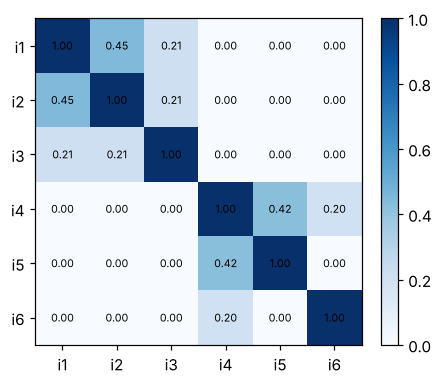

In [3]:
S = cosine_similarity(X_teks)
fig, ax = plt.subplots(figsize=(4.2, 3.6))
im = ax.imshow(S, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(6), [f"i{j+1}" for j in range(6)])
ax.set_yticks(range(6), [f"i{j+1}" for j in range(6)])
for a in range(6):
    for b in range(6):
        ax.text(b, a, f"{S[a, b]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, fraction=0.046)
fig.tight_layout()

dalam = S[:3, :3][np.triu_indices(3, 1)].mean()
antar = S[:3, 3:].mean()
print(f"rata-rata kemiripan dalam genre fantasi = {dalam:.3f} | fantasi-sains = {antar:.3f}")
assert dalam > antar

**Interpretasi.** Item sejenis hanya "dekat" jika berbagi kata. i2 dan i3 hampir tidak berbagi kata dengan i1 selain satu dua istilah, padahal sama-sama fantasi: **representasi menentukan batas kemampuan CBF**. Dengan satu-hot genre, ketiganya identik.

## 3. Eksperimen B: bobot rating mengubah profil

Profil adalah rata-rata berbobot. Ubah rating u2 pada i5 (sains) dari 1 menjadi 5 dan lihat skor tiga buku yang belum dinilai.

In [4]:
rows = []
for r5 in (1, 3, 5):
    s = skor({0: 4, 2: 5, 4: r5}, genre)
    rows.append({"rating_i5": r5, "i2_fantasi": s[1], "i4_sains": s[3], "i6_sains": s[5]})
tabel = pd.DataFrame(rows).set_index("rating_i5").round(3)
print(tabel)
assert tabel.loc[5, "i4_sains"] > tabel.loc[1, "i4_sains"]

           i2_fantasi  i4_sains  i6_sains
rating_i5                                
1               0.994     0.110     0.110
3               0.949     0.316     0.316
5               0.874     0.486     0.486


**Interpretasi.** Pada pembobotan ini, rating rendah hanya *mengecilkan* kontribusi item sains, bukan menjadikannya negatif. Profil CBF dengan rata-rata berbobot tidak punya konsep "tidak suka". Ada varian yang memusatkan rating (dikurangi rata-rata pengguna) agar rating rendah menjadi bobot negatif.

## 4. Eksperimen C: over-specialization

Pengguna dengan riwayat fantasi saja: apa yang direkomendasikan 3 teratas?

In [5]:
rating_fantasi = {0: 5, 1: 4}                    # hanya menilai i1 dan i2
s = skor(rating_fantasi, X_teks)
belum = [j for j in range(6) if j not in rating_fantasi]
urut = sorted(belum, key=lambda j: -s[j])
print("urutan rekomendasi:", [f"i{j+1}" for j in urut])
print("skor:", {f"i{j+1}": round(float(s[j]), 3) for j in urut})
assert urut[0] == 2          # i3 (fantasi) di puncak; seluruh item sains tertinggal

urutan rekomendasi: ['i3', 'i4', 'i5', 'i6']
skor: {'i3': 0.248, 'i4': 0.0, 'i5': 0.0, 'i6': 0.0}


**Interpretasi.** Profil yang dibentuk dari masa lalu hanya mencari hal yang mirip dengan masa lalu. Tidak ada mekanisme bawaan untuk menyodorkan sesuatu yang berbeda. Solusi di bab-bab lanjutan: re-ranking untuk keragaman, atau menggabungkan sinyal kolaboratif.

## Pertanyaan refleksi

1. Mengapa i2 dan i3 (sama-sama fantasi) tidak selalu dianggap mirip oleh TF-IDF?
2. Modifikasi apa pada fungsi `profil` yang membuat rating rendah menjadi sinyal negatif?
3. Pada pengguna baru tanpa riwayat, apa yang dikembalikan `profil`? Mengapa itu masalah cold-start sisi pengguna?